In [1]:
# ============================================================
# Cell 1 — Install packages
# ============================================================
!pip install -q -U timm "huggingface_hub<2.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 39.5 MB/s eta 0:00:00


In [2]:
# ============================================================
# Cell 2 — Imports, reproducibility, device
# ============================================================
import os, glob, json, math, time, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image, ImageFile
import timm
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
import matplotlib.pyplot as plt

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| timm", timm.__version__, "| device", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu128 | timm 1.0.30 | device cuda
GPU: Tesla T4


In [3]:
# ============================================================
# Cell 3 — Locate input datasets
# ============================================================
def find_input_dir(slug, base="/kaggle/input", max_depth=4):
    """Find a Kaggle dataset folder by its slug, whatever the mount layout."""
    base_depth = base.rstrip("/").count("/")
    for root, dirs, _ in os.walk(base):
        if os.path.basename(root) == slug:
            return root
        if root.count("/") - base_depth >= max_depth:
            dirs[:] = []
    raise FileNotFoundError(f"Dataset '{slug}' not found under {base}. Add it as input.")

for slug in ["edda-train-val-test-splits", "edda-d1-odir5k-clean",
             "edda-d2-mured-clean", "edda-d3-rfmid-clean"]:
    print(f"{slug:28s} -> {find_input_dir(slug)}")

edda-train-val-test-splits   -> /kaggle/input/datasets/bisusiddharth/edda-train-val-test-splits
edda-d1-odir5k-clean         -> /kaggle/input/datasets/bisusiddharth/edda-d1-odir5k-clean
edda-d2-mured-clean          -> /kaggle/input/datasets/bisusiddharth/edda-d2-mured-clean
edda-d3-rfmid-clean          -> /kaggle/input/datasets/bisusiddharth/edda-d3-rfmid-clean


In [4]:
# ============================================================
# Cell 4 — Configuration (the only cell to edit)
# ============================================================
# ---------------- Experiment ----------------
EXPERIMENT    = "D123"
TRAIN_SOURCES = ["D1", "D2", "D3"]
QUICK_TEST    = False                       # True = 3-epoch stability check; False = full training
MODEL_NAME    = "AttnFusion_ResNet50+RETFound"
FUSION_DESCRIPTION = ("cross-attention fusion: bidirectional cross-attention between RETFound "
                      "patch tokens and ResNet-50 spatial tokens, followed by a learned modality gate")

# ---------------- Data ----------------
SPLITS_SLUG  = "edda-train-val-test-splits"
IMAGE_SLUGS  = {"D1": "edda-d1-odir5k-clean",   # ODIR-5K
                "D2": "edda-d2-mured-clean",    # MuReD
                "D3": "edda-d3-rfmid-clean"}    # RFMiD
ALL_SOURCES  = list(IMAGE_SLUGS)
FILE_COL, SOURCE_COL, PATH_COL, SPLIT_COL = "filename", "source_dataset", "image_path", "split"
CLASSES      = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]
DISEASE_CLASSES = [c for c in CLASSES if c != "Normal"]

# ---------------- Backbones ----------------
RETFOUND_REPO = "YukunZhou/RETFound_mae_natureCFP"
RETFOUND_FILE = "RETFound_mae_natureCFP.pth"
VIT_ARCH      = "vit_large_patch16_224"    # Transformer branch (RETFound)
CNN_ARCH      = "resnet50.a1_in1k"         # CNN branch (ImageNet-1k)

# ---------------- Attention fusion ----------------
FUSION_DIM      = 512                      # shared token dimension
ATTN_HEADS      = 8
ATTN_LAYERS     = 1                        # cross-attention blocks per direction
ATTN_DROPOUT    = 0.1
FUSION_DROPOUT  = 0.3
FUSION_LR_SCALE = 0.2                      # fusion layers train at 0.2 x BASE_LR (stability fix)

# ---------------- Training ----------------
IMG_SIZE        = 224
BATCH_SIZE      = 16
ACCUM_STEPS     = 2                        # effective batch = 32
EPOCHS          = 3 if QUICK_TEST else 30  # quick test reaches peak LR at epoch 2
WARMUP_EPOCHS   = 1 if QUICK_TEST else 5
BASE_LR         = 5e-3 * BATCH_SIZE * ACCUM_STEPS / 256   # 6.25e-4
MIN_LR          = 1e-6
WEIGHT_DECAY    = 0.05
VIT_LAYER_DECAY = 0.65
VIT_DROP_PATH   = 0.2
CNN_DROP_PATH   = 0.05
CNN_LR_SCALE    = 0.5
PATIENCE        = 8
NUM_WORKERS     = 4
SEED            = 42

# ---------------- Output ----------------
RUN_DIR = f"/kaggle/working/AttnFusion_{EXPERIMENT}" + ("_quicktest" if QUICK_TEST else "")
os.makedirs(RUN_DIR, exist_ok=True)
BEST_CHECKPOINT = f"{RUN_DIR}/attn_fusion_{EXPERIMENT}_best.pth"

seed_everything(SEED)
print(f"{MODEL_NAME} | train on {EXPERIMENT} {TRAIN_SOURCES} | epochs {EPOCHS} "
      f"| base LR {BASE_LR:.2e} | fusion LR scale {FUSION_LR_SCALE} | quick_test={QUICK_TEST}"
      f"\nOutputs -> {RUN_DIR}")

AttnFusion_ResNet50+RETFound | train on D123 ['D1', 'D2', 'D3'] | epochs 30 | base LR 6.25e-04 | fusion LR scale 0.2 | quick_test=False
Outputs -> /kaggle/working/AttnFusion_D123


In [5]:
# ============================================================
# Cell 5 — Build train/val/test splits + leakage check
# ============================================================
SPLITS_DIR = find_input_dir(SPLITS_SLUG)

def load_split_csv(source):
    hits = glob.glob(f"{SPLITS_DIR}/**/split_{source}.csv", recursive=True)
    assert hits, f"split_{source}.csv not found in {SPLITS_DIR}"
    return pd.read_csv(hits[0])

_image_index = None
def get_image_index():
    """filename -> full path across all image datasets (fallback for stale paths)."""
    global _image_index
    if _image_index is None:
        _image_index = {}
        for slug in IMAGE_SLUGS.values():
            for root, _, files in os.walk(find_input_dir(slug)):
                for f in files:
                    _image_index.setdefault(f, os.path.join(root, f))
    return _image_index

def clean_split(df, source):
    df = df.copy()
    df[CLASSES] = df[CLASSES].fillna(0).astype(int).clip(0, 1)
    exists = df[PATH_COL].map(os.path.exists)
    if not exists.all():
        print(f"[{source}] {(~exists).sum()} stored paths missing, resolving by filename...")
        df.loc[~exists, PATH_COL] = df.loc[~exists, FILE_COL].map(get_image_index())
    n_missing = df[PATH_COL].isna().sum()
    if n_missing:
        print(f"[{source}] WARNING: {n_missing} images not found, dropped")
    df = df.dropna(subset=[PATH_COL]).reset_index(drop=True)
    df["img_path"] = df[PATH_COL]
    return df

# Clean per-source splits (the combined split_D12/D123 files are NOT used: they leak)
per_source = {s: clean_split(load_split_csv(s), s) for s in ALL_SOURCES}
for s, d in per_source.items():
    assert d.groupby(FILE_COL)[SPLIT_COL].nunique().max() == 1, f"{s}: image in >1 split"

def select(split, sources):
    return pd.concat([per_source[s][per_source[s][SPLIT_COL] == split] for s in sources],
                     ignore_index=True)

train_df = select("train", TRAIN_SOURCES)
val_df   = select("val",   TRAIN_SOURCES)

# Test sets — names identical to the RETFound run so results can be paired
TEST_SETS = {f"{EXPERIMENT}_in_domain": select("test", TRAIN_SOURCES)}
for s in ALL_SOURCES:
    TEST_SETS[f"{s}_test"] = select("test", [s])
DOMAIN = {f"{s}_test": ("in-domain" if s in TRAIN_SOURCES else "OUT-OF-DOMAIN") for s in ALL_SOURCES}
DOMAIN[f"{EXPERIMENT}_in_domain"] = "in-domain (pooled)"

# Leakage check
seen_files = set(train_df[FILE_COL]) | set(val_df[FILE_COL])
for name, d in TEST_SETS.items():
    assert not d[FILE_COL].isin(seen_files).any(), f"LEAKAGE detected in {name}"
assert not set(train_df[FILE_COL]) & set(val_df[FILE_COL]), "train/val overlap"
print("Leakage check passed: train, val and test are disjoint.\n")

data_summary = pd.DataFrame({n: d[CLASSES].sum() for n, d in
                             [("train", train_df), ("val", val_df)] + list(TEST_SETS.items())})
data_summary.loc["N images"] = [len(train_df), len(val_df)] + [len(d) for d in TEST_SETS.values()]
display(data_summary)
data_summary.to_csv(f"{RUN_DIR}/data_summary.csv")
print("Train by source:", train_df[SOURCE_COL].value_counts().to_dict())

Leakage check passed: train, val and test are disjoint.



,train,val,D123_in_domain,D1_test,D2_test,D3_test
Normal,2773,595,595,431,64,100
DR,1865,398,398,241,63,94
Glaucoma,672,142,143,43,33,67
AMD,402,84,86,40,20,26
Myopia,335,72,70,35,11,24
N images,5882,1259,1260,790,182,288


Train by source: {'D1': 3682, 'D3': 1347, 'D2': 853}


In [6]:
# ============================================================
# Cell 6 — Download RETFound weights (Hugging Face)
# ============================================================
from huggingface_hub import hf_hub_download, list_repo_files
from kaggle_secrets import UserSecretsClient

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
try:
    RETFOUND_CKPT_PATH = hf_hub_download(RETFOUND_REPO, RETFOUND_FILE, token=HF_TOKEN)
except Exception as e:
    print("Download failed:", e)
    print("Files in repo:", list_repo_files(RETFOUND_REPO, token=HF_TOKEN))
    raise
print("RETFound weights:", RETFOUND_CKPT_PATH,
      f"({os.path.getsize(RETFOUND_CKPT_PATH)/1e9:.2f} GB)")

RETFound_mae_natureCFP.pth: reconstructing file:   0%|          |  0.00B / 3.95GB            

RETFound_mae_natureCFP.pth: downloading bytes:           |  0.00B            

RETFound weights: /root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth (3.95 GB)


In [7]:
# ============================================================
# Cell 7 — Dataset, augmentation, data loaders
# ============================================================
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)  # used by both backbones

train_transform = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FundusDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["img_path"].values
        self.labels = df[CLASSES].values.astype("float32")
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert("RGB")
        return self.transform(image), torch.from_numpy(self.labels[i])

def make_loader(df, transform, shuffle, drop_last=False):
    return DataLoader(FundusDataset(df, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=True, drop_last=drop_last,
                      persistent_workers=NUM_WORKERS > 0)

train_loader = make_loader(train_df, train_transform, shuffle=True, drop_last=True)
val_loader   = make_loader(val_df,   eval_transform,  shuffle=False)

sample_images, sample_labels = next(iter(train_loader))
print("batch:", tuple(sample_images.shape), tuple(sample_labels.shape),
      "| train batches/epoch:", len(train_loader))

batch: (16, 3, 224, 224) (16, 5) | train batches/epoch: 367


In [8]:
# ============================================================
# Cell 8 — Attention fusion: ResNet-50 (CNN) + RETFound (Transformer)
# ============================================================
class CrossAttentionBlock(nn.Module):
    """Pre-norm cross-attention: query tokens from one branch attend to the other branch,
    followed by a feed-forward network. Both steps are residual."""
    def __init__(self, dim, heads, dropout, mlp_ratio=4):
        super().__init__()
        self.norm_q   = nn.LayerNorm(dim)
        self.norm_kv  = nn.LayerNorm(dim)
        self.attn     = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.norm_ffn = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(dim * mlp_ratio, dim), nn.Dropout(dropout))

    def forward(self, query_tokens, context_tokens):
        context = self.norm_kv(context_tokens)
        attended, _ = self.attn(self.norm_q(query_tokens), context, context, need_weights=False)
        x = query_tokens + attended
        return x + self.ffn(self.norm_ffn(x))


class ResNetRETFoundAttentionFusion(nn.Module):
    """RETFound patch tokens and ResNet-50 spatial tokens exchange information through
    bidirectional cross-attention; the pooled representations are combined by a learned,
    per-image modality gate. The fusion part runs in fp32 for numerical stability."""

    def __init__(self, num_classes, retfound_ckpt_path):
        super().__init__()
        # ---- Transformer branch: RETFound ViT-L/16 ----
        self.vit = timm.create_model(VIT_ARCH, pretrained=False, num_classes=0,
                                     img_size=IMG_SIZE, global_pool="avg",
                                     drop_path_rate=VIT_DROP_PATH)
        self._load_retfound_weights(retfound_ckpt_path)

        # ---- CNN branch: ResNet-50 (ImageNet) ----
        self.cnn = timm.create_model(CNN_ARCH, pretrained=True, num_classes=0,
                                     drop_path_rate=CNN_DROP_PATH)

        # ---- Token projections to a shared 512-d space ----
        vit_dim, cnn_dim = self.vit.num_features, self.cnn.num_features      # 1024, 2048
        self.vit_token_proj = nn.Sequential(nn.LayerNorm(vit_dim), nn.Linear(vit_dim, FUSION_DIM))
        self.cnn_token_proj = nn.Sequential(nn.LayerNorm(cnn_dim), nn.Linear(cnn_dim, FUSION_DIM))
        n_cnn_tokens = (IMG_SIZE // 32) ** 2                                  # 7 x 7 = 49
        self.cnn_pos_embed = nn.Parameter(torch.zeros(1, n_cnn_tokens, FUSION_DIM))
        nn.init.trunc_normal_(self.cnn_pos_embed, std=0.02)

        # ---- Bidirectional cross-attention ----
        self.vit_attends_cnn = nn.ModuleList(
            [CrossAttentionBlock(FUSION_DIM, ATTN_HEADS, ATTN_DROPOUT) for _ in range(ATTN_LAYERS)])
        self.cnn_attends_vit = nn.ModuleList(
            [CrossAttentionBlock(FUSION_DIM, ATTN_HEADS, ATTN_DROPOUT) for _ in range(ATTN_LAYERS)])

        # ---- Modality gate + classifier ----
        self.modality_gate = nn.Linear(2 * FUSION_DIM, 2)       # -> [w_transformer, w_cnn]
        nn.init.zeros_(self.modality_gate.weight)                # starts at equal weights 0.5 / 0.5
        nn.init.zeros_(self.modality_gate.bias)
        self.fused_norm = nn.LayerNorm(FUSION_DIM)
        self.classifier = nn.Sequential(nn.Dropout(FUSION_DROPOUT),
                                        nn.Linear(FUSION_DIM, num_classes))
        nn.init.trunc_normal_(self.classifier[1].weight, std=2e-5)
        nn.init.zeros_(self.classifier[1].bias)
        self.last_gate = None                                    # stored for Cell 15

    def _load_retfound_weights(self, ckpt_path):
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        state = ckpt.get("model", ckpt.get("state_dict", ckpt))
        state = {k.replace("module.", ""): v for k, v in state.items()}
        target = self.vit.state_dict()
        state = {k: v for k, v in state.items() if k in target}
        if state["pos_embed"].shape != target["pos_embed"].shape:
            from timm.layers import resample_abs_pos_embed
            state["pos_embed"] = resample_abs_pos_embed(state["pos_embed"],
                                                        new_size=self.vit.patch_embed.grid_size,
                                                        num_prefix_tokens=1)
        msg = self.vit.load_state_dict(state, strict=False)
        print(f"RETFound: loaded {len(state)}/{len(target)} tensors. Missing:", msg.missing_keys)
        assert set(msg.missing_keys) <= {"fc_norm.weight", "fc_norm.bias"}, "RETFound not loaded!"

    def forward(self, x):
        # 1) Token sequences from each backbone (mixed precision is fine here)
        vit_tokens = self.vit.forward_features(x)[:, self.vit.num_prefix_tokens:]  # (B, 196, 1024)
        cnn_tokens = self.cnn.forward_features(x).flatten(2).transpose(1, 2)       # (B, 49, 2048)

        # 2) Fusion runs in full fp32 precision to avoid fp16 overflow in attention
        with torch.autocast(device_type="cuda", enabled=False):
            vit_tokens = self.vit_token_proj(vit_tokens.float())                       # (B, 196, 512)
            cnn_tokens = self.cnn_token_proj(cnn_tokens.float()) + self.cnn_pos_embed  # (B, 49, 512)

            for vit_block, cnn_block in zip(self.vit_attends_cnn, self.cnn_attends_vit):
                vit_tokens, cnn_tokens = vit_block(vit_tokens, cnn_tokens), cnn_block(cnn_tokens, vit_tokens)

            vit_vec, cnn_vec = vit_tokens.mean(dim=1), cnn_tokens.mean(dim=1)
            gate = torch.softmax(self.modality_gate(torch.cat([vit_vec, cnn_vec], dim=1)), dim=1)
            self.last_gate = gate.detach()
            fused = self.fused_norm(gate[:, :1] * vit_vec + gate[:, 1:] * cnn_vec)
            return self.classifier(fused)


model = ResNetRETFoundAttentionFusion(len(CLASSES), RETFOUND_CKPT_PATH)
model.vit.set_grad_checkpointing(True)                 # saves GPU memory on ViT-L
model = model.to(DEVICE)

def n_params(module):
    return sum(p.numel() for p in module.parameters()) / 1e6
fusion_modules = [model.vit_token_proj, model.cnn_token_proj, model.vit_attends_cnn,
                  model.cnn_attends_vit, model.modality_gate, model.fused_norm, model.classifier]
fusion_params = sum(n_params(m) for m in fusion_modules) + model.cnn_pos_embed.numel() / 1e6
print(f"RETFound branch: {n_params(model.vit):.1f}M | ResNet-50 branch: {n_params(model.cnn):.1f}M | "
      f"attention-fusion modules: {fusion_params:.2f}M | total: {n_params(model):.1f}M")

model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    out = model(sample_images[:2].to(DEVICE))
print("Output shape check:", tuple(out.shape), "| finite:", torch.isfinite(out).all().item(),
      "| initial gate [w_vit, w_cnn]:", model.last_gate[0].float().cpu().numpy().round(2))

RETFound: loaded 292/294 tensors. Missing: ['fc_norm.weight', 'fc_norm.bias']


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

RETFound branch: 303.3M | ResNet-50 branch: 23.5M | attention-fusion modules: 7.92M | total: 334.7M
Output shape check: (2, 5) | finite: True | initial gate [w_vit, w_cnn]: [0.5 0.5]


In [9]:
# ============================================================
# Cell 9 — Optimizer (per-branch LRs), LR schedule, loss
# ============================================================
def build_param_groups(model):
    """RETFound: layer-wise LR decay | ResNet-50: CNN_LR_SCALE | fusion layers: FUSION_LR_SCALE."""
    n_vit_layers = len(model.vit.blocks) + 1
    groups = {}
    def add(param, tag, lr_scale, no_decay):
        key = f"{tag}_{'nodecay' if no_decay else 'decay'}"
        if key not in groups:
            groups[key] = {"params": [], "lr_scale": lr_scale, "tag": tag,
                           "weight_decay": 0.0 if no_decay else WEIGHT_DECAY}
        groups[key]["params"].append(param)

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        no_decay = param.ndim == 1 or name.endswith(("cls_token", "pos_embed"))
        if name.startswith("vit."):
            sub = name[len("vit."):]
            if sub in ("cls_token", "pos_embed") or sub.startswith("patch_embed"):
                layer_id = 0
            elif sub.startswith("blocks."):
                layer_id = int(sub.split(".")[1]) + 1
            else:
                layer_id = n_vit_layers
            add(param, f"vit_L{layer_id}", VIT_LAYER_DECAY ** (n_vit_layers - layer_id), no_decay)
        elif name.startswith("cnn."):
            add(param, "cnn", CNN_LR_SCALE, no_decay)
        else:
            add(param, "fusion_head", FUSION_LR_SCALE, no_decay)
    return list(groups.values())

param_groups = build_param_groups(model)
optimizer = torch.optim.AdamW(param_groups, lr=BASE_LR, betas=(0.9, 0.999))
grad_scaler = torch.amp.GradScaler("cuda")

STEPS_PER_EPOCH = math.ceil(len(train_loader) / ACCUM_STEPS)
TOTAL_STEPS     = EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS    = WARMUP_EPOCHS * STEPS_PER_EPOCH

def set_learning_rate(step):
    """Linear warm-up, then cosine decay; each group scaled by its lr_scale."""
    if step < WARMUP_STEPS:
        lr = BASE_LR * step / max(1, WARMUP_STEPS)
    else:
        progress = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
        lr = MIN_LR + (BASE_LR - MIN_LR) * 0.5 * (1 + math.cos(math.pi * progress))
    for g in optimizer.param_groups:
        g["lr"] = lr * g["lr_scale"]
    return lr

# Class-imbalance-aware multi-label loss
n_pos = train_df[CLASSES].sum().values
n_neg = len(train_df) - n_pos
pos_weight = torch.tensor(np.clip(n_neg / np.maximum(n_pos, 1), 1, 10),
                          dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f"{len(param_groups)} param groups | peak LR: fusion layers {BASE_LR*FUSION_LR_SCALE:.2e}, "
      f"ResNet-50 {BASE_LR*CNN_LR_SCALE:.2e}, RETFound top block {BASE_LR*VIT_LAYER_DECAY:.2e}")
print("pos_weight:", dict(zip(CLASSES, pos_weight.cpu().numpy().round(2))))

55 param groups | peak LR: fusion layers 1.25e-04, ResNet-50 3.13e-04, RETFound top block 4.06e-04
pos_weight: {'Normal': np.float32(1.12), 'DR': np.float32(2.15), 'Glaucoma': np.float32(7.75), 'AMD': np.float32(10.0), 'Myopia': np.float32(10.0)}


In [10]:
# ============================================================
# Cell 10 — Training, prediction and metric functions (with NaN guards)
# ============================================================
def train_one_epoch(step):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    running_loss, n_seen, lr, n_skipped = 0.0, 0, 0.0, 0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(images), labels) / ACCUM_STEPS
        if not torch.isfinite(loss):                      # safety: skip a bad batch instead of crashing
            n_skipped += 1
            optimizer.zero_grad(set_to_none=True)
            continue
        grad_scaler.scale(loss).backward()
        if (i + 1) % ACCUM_STEPS == 0 or (i + 1) == len(train_loader):
            lr = set_learning_rate(step)
            grad_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            grad_scaler.step(optimizer); grad_scaler.update()
            optimizer.zero_grad(set_to_none=True)
            step += 1
        running_loss += loss.item() * ACCUM_STEPS * images.size(0)
        n_seen += images.size(0)
    if n_skipped:
        print(f"  WARNING: skipped {n_skipped} batches with non-finite loss")
    return running_loss / max(n_seen, 1), step, lr

@torch.no_grad()
def predict(loader):
    model.eval()
    all_probs, all_labels = [], []
    for images, labels in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            all_probs.append(torch.sigmoid(model(images.to(DEVICE)).float()).cpu())
        all_labels.append(labels)
    probs = torch.cat(all_probs)
    n_bad = (~torch.isfinite(probs)).sum().item()
    if n_bad:
        print(f"  WARNING: {n_bad} non-finite predictions replaced with 0.5")
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
    return probs.numpy(), torch.cat(all_labels).numpy()

def compute_metrics(y_true, y_prob, thresholds=None):
    thresholds = np.full(len(CLASSES), 0.5) if thresholds is None else thresholds
    rows = {}
    for j, c in enumerate(CLASSES):
        yt, yp = y_true[:, j], y_prob[:, j]
        rows[c] = {
            "AUC": roc_auc_score(yt, yp) if 0 < yt.sum() < len(yt) else np.nan,
            "AP":  average_precision_score(yt, yp) if yt.sum() > 0 else np.nan,
            "F1":  f1_score(yt, (yp >= thresholds[j]).astype(int), zero_division=0),
            "support": int(yt.sum()),
        }
    table = pd.DataFrame(rows).T.astype(float)
    for row_name, cols in [("macro", CLASSES), ("macro_disease", DISEASE_CLASSES)]:
        table.loc[row_name] = [table.loc[cols, "AUC"].mean(), table.loc[cols, "AP"].mean(),
                               table.loc[cols, "F1"].mean(), table.loc[cols, "support"].sum()]
    return table.round(4)

def tune_thresholds(y_true, y_prob):
    """Per-class threshold maximising F1 on the validation set."""
    grid = np.linspace(0.05, 0.95, 91)
    return np.array([grid[np.argmax([f1_score(y_true[:, j], (y_prob[:, j] >= t).astype(int),
                                              zero_division=0) for t in grid])]
                     for j in range(y_true.shape[1])])

In [11]:
# Sanity check — all four fixes are in place
import inspect
print("1) FUSION_LR_SCALE =", FUSION_LR_SCALE)
print("2) fp32 fusion in forward:", "enabled=False" in inspect.getsource(ResNetRETFoundAttentionFusion.forward))
print("3) fusion-layer LR scale:", {g["lr_scale"] for g in optimizer.param_groups if g["tag"] == "fusion_head"})
print("4) NaN guards:", "isfinite" in inspect.getsource(train_one_epoch),
      "isfinite" in inspect.getsource(predict))

1) FUSION_LR_SCALE = 0.2
2) fp32 fusion in forward: True
3) fusion-layer LR scale: {0.2}
4) NaN guards: True True


In [12]:
# ============================================================
# Cell 11 — Training loop (best checkpoint by val macro-AUC)
# ============================================================
best_val_auc, epochs_without_improvement, global_step, history = -1.0, 0, 0, []

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, global_step, lr = train_one_epoch(global_step)
    val_probs, val_labels = predict(val_loader)
    val_metrics = compute_metrics(val_labels, val_probs)
    val_auc, val_f1 = val_metrics.loc["macro", "AUC"], val_metrics.loc["macro", "F1"]
    history.append({"epoch": epoch, "train_loss": train_loss, "val_macro_auc": val_auc,
                    "val_macro_f1": val_f1, "lr": lr})

    note = ""
    if val_auc > best_val_auc:
        best_val_auc, epochs_without_improvement, note = val_auc, 0, "  <-- best, saved"
        torch.save(model.state_dict(), BEST_CHECKPOINT)
    else:
        epochs_without_improvement += 1
    print(f"Ep {epoch:02d} | loss {train_loss:.4f} | val AUC {val_auc:.4f} | val F1 {val_f1:.4f} "
          f"| lr {lr:.2e} | {time.time()-t0:.0f}s{note}")
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

pd.DataFrame(history).to_csv(f"{RUN_DIR}/history.csv", index=False)
print("Best val macro-AUC:", round(best_val_auc, 4))

Ep 01 | loss 0.9792 | val AUC 0.7127 | val F1 0.4096 | lr 1.24e-04 | 265s  <-- best, saved
Ep 02 | loss 0.8245 | val AUC 0.8171 | val F1 0.5282 | lr 2.49e-04 | 284s  <-- best, saved
Ep 03 | loss 0.6749 | val AUC 0.8722 | val F1 0.6172 | lr 3.74e-04 | 285s  <-- best, saved
Ep 04 | loss 0.5818 | val AUC 0.8947 | val F1 0.6184 | lr 4.99e-04 | 284s  <-- best, saved
Ep 05 | loss 0.5237 | val AUC 0.8921 | val F1 0.6625 | lr 6.24e-04 | 282s
Ep 06 | loss 0.4963 | val AUC 0.9200 | val F1 0.6591 | lr 6.23e-04 | 283s  <-- best, saved
Ep 07 | loss 0.4613 | val AUC 0.9115 | val F1 0.7240 | lr 6.15e-04 | 282s
Ep 08 | loss 0.4364 | val AUC 0.9227 | val F1 0.7157 | lr 6.03e-04 | 284s  <-- best, saved
Ep 09 | loss 0.4091 | val AUC 0.9243 | val F1 0.7499 | lr 5.87e-04 | 284s  <-- best, saved
Ep 10 | loss 0.3781 | val AUC 0.9338 | val F1 0.7454 | lr 5.66e-04 | 284s  <-- best, saved
Ep 11 | loss 0.3599 | val AUC 0.9307 | val F1 0.7577 | lr 5.41e-04 | 283s
Ep 12 | loss 0.3362 | val AUC 0.9320 | val F1 0.73

In [13]:
# ============================================================
# Cell 12 — Test evaluation (pooled + per source)
# ============================================================
model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=DEVICE))

val_probs, val_labels = predict(val_loader)
THRESHOLDS = tune_thresholds(val_labels, val_probs)          # tuned on VAL only
print("Thresholds:", {c: round(float(t), 2) for c, t in zip(CLASSES, THRESHOLDS)})

test_results, test_predictions, overview_rows = {}, [], []
for test_name, test_df in TEST_SETS.items():
    test_probs, test_labels = predict(make_loader(test_df, eval_transform, shuffle=False))
    metrics = compute_metrics(test_labels, test_probs, THRESHOLDS)
    test_results[test_name] = metrics
    print(f"\n=== {test_name} [{DOMAIN[test_name]}] | {MODEL_NAME} trained on {EXPERIMENT} "
          f"| n={len(test_df)} ===")
    display(metrics)

    overview_rows.append({"model": MODEL_NAME, "train_exp": EXPERIMENT, "test_set": test_name,
                          "domain": DOMAIN[test_name], "n": len(test_df),
                          "macro_AUC": metrics.loc["macro", "AUC"],
                          "macro_AP":  metrics.loc["macro", "AP"],
                          "macro_F1":  metrics.loc["macro", "F1"],
                          "disease_AUC": metrics.loc["macro_disease", "AUC"],
                          "disease_AP":  metrics.loc["macro_disease", "AP"]})

    preds = test_df[[FILE_COL, SOURCE_COL] + CLASSES].copy()
    for j, c in enumerate(CLASSES):
        preds[f"prob_{c}"] = test_probs[:, j]
    preds["test_set"] = test_name
    test_predictions.append(preds)

overview = pd.DataFrame(overview_rows)
print("\n=== Overview ===")
display(overview)

overview.to_csv(f"{RUN_DIR}/overview.csv", index=False)
pd.concat(test_results, names=["test_set", "class"]).to_csv(f"{RUN_DIR}/test_metrics.csv")
pd.concat(test_predictions).to_csv(f"{RUN_DIR}/test_predictions.csv", index=False)
json.dump({"model": MODEL_NAME,
           "branches": {"transformer": f"RETFound_mae_natureCFP ({VIT_ARCH})", "cnn": CNN_ARCH},
           "fusion": FUSION_DESCRIPTION,
           "experiment": EXPERIMENT, "best_val_macro_auc": float(best_val_auc),
           "thresholds": dict(zip(CLASSES, THRESHOLDS.tolist()))},
          open(f"{RUN_DIR}/summary.json", "w"), indent=2)
print("\nSaved to", RUN_DIR)

Thresholds: {'Normal': 0.52, 'DR': 0.41, 'Glaucoma': 0.71, 'AMD': 0.89, 'Myopia': 0.89}

=== D123_in_domain [in-domain (pooled)] | AttnFusion_ResNet50+RETFound trained on D123 | n=1260 ===


,AUC,AP,F1,support
Normal,0.9128,0.8838,0.8436,595.0
DR,0.9148,0.8770,0.7746,398.0
Glaucoma,0.9485,0.7914,0.7474,143.0
AMD,0.9460,0.8095,0.7515,86.0
Myopia,0.9975,0.9298,0.9065,70.0
macro,0.9439,0.8583,0.8047,1292.0
macro_disease,0.9517,0.8520,0.7950,697.0



=== D1_test [in-domain] | AttnFusion_ResNet50+RETFound trained on D123 | n=790 ===


,AUC,AP,F1,support
Normal,0.8327,0.8119,0.8190,431.0
DR,0.8539,0.7970,0.6941,241.0
Glaucoma,0.9178,0.5204,0.5500,43.0
AMD,0.9092,0.7090,0.6494,40.0
Myopia,0.9987,0.9613,0.9118,35.0
macro,0.9025,0.7599,0.7249,790.0
macro_disease,0.9199,0.7469,0.7013,359.0



=== D2_test [in-domain] | AttnFusion_ResNet50+RETFound trained on D123 | n=182 ===


,AUC,AP,F1,support
Normal,0.9719,0.9525,0.8837,64.0
DR,0.9564,0.9416,0.8444,63.0
Glaucoma,0.9854,0.9428,0.8955,33.0
AMD,0.9528,0.8446,0.8000,20.0
Myopia,0.9989,0.9842,0.9167,11.0
macro,0.9731,0.9332,0.8681,191.0
macro_disease,0.9734,0.9283,0.8642,127.0



=== D3_test [in-domain] | AttnFusion_ResNet50+RETFound trained on D123 | n=288 ===


,AUC,AP,F1,support
Normal,0.9886,0.9718,0.9327,100.0
DR,0.9891,0.9839,0.9418,94.0
Glaucoma,0.9481,0.8608,0.7887,67.0
AMD,0.9956,0.9551,0.8679,26.0
Myopia,0.9942,0.9079,0.8936,24.0
macro,0.9831,0.9359,0.8850,311.0
macro_disease,0.9817,0.9269,0.8730,211.0



=== Overview ===


,model,train_exp,test_set,domain,n,macro_AUC,macro_AP,macro_F1,disease_AUC,disease_AP
0,AttnFusion_ResNet50+RETFound,D123,D123_in_domain,in-domain (pooled),1260,0.9439,0.8583,0.8047,0.9517,0.8520
1,AttnFusion_ResNet50+RETFound,D123,D1_test,in-domain,790,0.9025,0.7599,0.7249,0.9199,0.7469
2,AttnFusion_ResNet50+RETFound,D123,D2_test,in-domain,182,0.9731,0.9332,0.8681,0.9734,0.9283
3,AttnFusion_ResNet50+RETFound,D123,D3_test,in-domain,288,0.9831,0.9359,0.8850,0.9817,0.9269



Saved to /kaggle/working/AttnFusion_D123


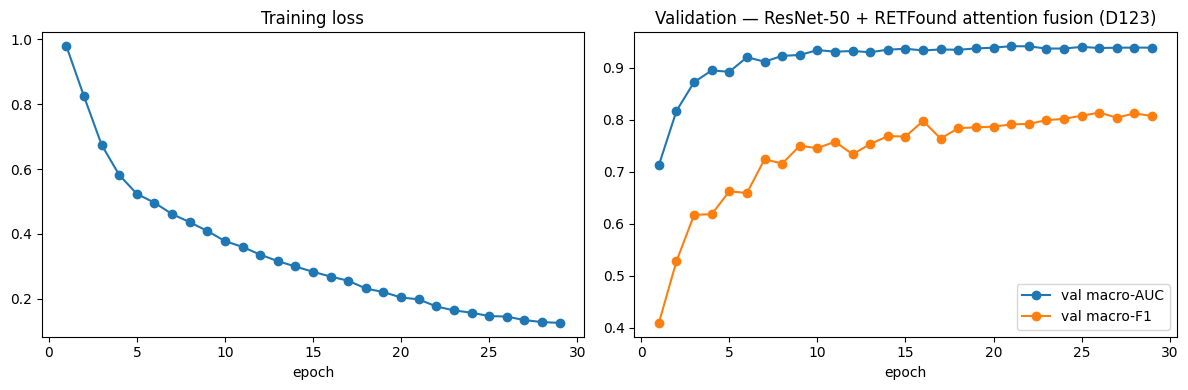

In [14]:
# ============================================================
# Cell 13 — Training curves
# ============================================================
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist.train_loss, marker="o")
ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist.epoch, hist.val_macro_auc, marker="o", label="val macro-AUC")
ax[1].plot(hist.epoch, hist.val_macro_f1,  marker="o", label="val macro-F1")
ax[1].set_title(f"Validation — ResNet-50 + RETFound attention fusion ({EXPERIMENT})")
ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=150); plt.show()

In [15]:
# ============================================================
# Cell 14 — Bootstrap 95% confidence intervals (AUC)
# ============================================================
all_test_preds = pd.concat(test_predictions, ignore_index=True)
rng = np.random.default_rng(SEED)
N_BOOTSTRAP = 1000
ci_rows = []

for test_name, g in all_test_preds.groupby("test_set", sort=False):
    y_true = g[CLASSES].values
    y_prob = g[[f"prob_{c}" for c in CLASSES]].values
    n = len(g)
    boot = {c: [] for c in CLASSES + ["macro"]}
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, n, n)
        yt, yp = y_true[idx], y_prob[idx]
        aucs = [roc_auc_score(yt[:, j], yp[:, j]) if 0 < yt[:, j].sum() < n else np.nan
                for j in range(len(CLASSES))]
        for c, a in zip(CLASSES, aucs):
            if not np.isnan(a):
                boot[c].append(a)
        if not np.isnan(aucs).any():
            boot["macro"].append(np.mean(aucs))
    point = {c: roc_auc_score(y_true[:, j], y_prob[:, j]) for j, c in enumerate(CLASSES)}
    point["macro"] = np.mean(list(point.values()))
    for c in CLASSES + ["macro"]:
        lo, hi = np.percentile(boot[c], [2.5, 97.5])
        ci_rows.append({"test_set": test_name, "class": c, "AUC": point[c],
                        "CI_low": lo, "CI_high": hi})

auc_ci = pd.DataFrame(ci_rows)
auc_ci["AUC [95% CI]"] = auc_ci.apply(
    lambda r: f"{r.AUC:.3f} [{r.CI_low:.3f}-{r.CI_high:.3f}]", axis=1)
display(auc_ci.pivot(index="class", columns="test_set", values="AUC [95% CI]")
              .reindex(CLASSES + ["macro"]))
auc_ci.round(4).to_csv(f"{RUN_DIR}/auc_bootstrap_ci.csv", index=False)
print("Saved:", f"{RUN_DIR}/auc_bootstrap_ci.csv")

test_set,D123_in_domain,D1_test,D2_test,D3_test
class,,,,
Normal,0.913 [0.897-0.928],0.833 [0.801-0.861],0.972 [0.950-0.988],0.989 [0.976-0.997]
DR,0.915 [0.898-0.933],0.854 [0.823-0.885],0.956 [0.924-0.983],0.989 [0.976-0.998]
Glaucoma,0.948 [0.927-0.966],0.918 [0.869-0.956],0.985 [0.965-0.998],0.948 [0.915-0.975]
AMD,0.946 [0.916-0.973],0.909 [0.844-0.962],0.953 [0.903-0.989],0.996 [0.989-0.999]
Myopia,0.997 [0.995-0.999],0.999 [0.997-1.000],0.999 [0.995-1.000],0.994 [0.985-1.000]
macro,0.944 [0.934-0.954],0.902 [0.882-0.921],0.973 [0.957-0.986],0.983 [0.973-0.991]


Saved: /kaggle/working/AttnFusion_D123/auc_bootstrap_ci.csv


In [16]:
# ============================================================
# Cell 15 — Modality gate analysis: how much does each image rely on the CNN?
# ============================================================
model.eval()                       # best checkpoint already loaded in Cell 12
gate_rows = []
with torch.no_grad():
    for test_name, test_df in TEST_SETS.items():
        gates = []
        for images, _ in make_loader(test_df, eval_transform, shuffle=False):
            with torch.autocast("cuda", dtype=torch.float16):
                model(images.to(DEVICE))
            gates.append(model.last_gate.float().cpu())
        cnn_weight = torch.cat(gates).numpy()[:, 1]               # w_cnn per image
        labels = test_df[CLASSES].values
        row = {"test_set": test_name, "all images": cnn_weight.mean()}
        for j, c in enumerate(CLASSES):
            positives = labels[:, j] == 1
            row[c] = cnn_weight[positives].mean() if positives.any() else np.nan
        gate_rows.append(row)

gate_table = pd.DataFrame(gate_rows).set_index("test_set").round(3)
print("Mean ResNet-50 (CNN) gate weight per test set and per true class "
      "(RETFound weight = 1 − value; 0.5 = equal reliance)")
display(gate_table)
gate_table.to_csv(f"{RUN_DIR}/modality_gate_weights.csv")
print("Saved:", f"{RUN_DIR}/modality_gate_weights.csv")

Mean ResNet-50 (CNN) gate weight per test set and per true class (RETFound weight = 1 − value; 0.5 = equal reliance)


,all images,Normal,DR,Glaucoma,AMD,Myopia
test_set,,,,,,
D123_in_domain,0.340,0.254,0.372,0.370,0.737,0.486
D1_test,0.291,0.253,0.308,0.256,0.636,0.285
D2_test,0.433,0.286,0.483,0.397,0.779,0.696
D3_test,0.417,0.238,0.463,0.430,0.860,0.682


Saved: /kaggle/working/AttnFusion_D123/modality_gate_weights.csv
